lab 7

Instructor Name: Attique-ur-Rehman

Student Name: Zoha Adnan

Sap Id: 70177706

In [1]:
import numpy as np

image = np.array([
    [3, 1, 0, 2, 1],
    [2, 0, 1, 3, 0],
    [4, 1, 0, 1, 2],
    [1, 3, 2, 0, 1],
    [0, 2, 1, 4, 2],
])
print(image)

[[3 1 0 2 1]
 [2 0 1 3 0]
 [4 1 0 1 2]
 [1 3 2 0 1]
 [0 2 1 4 2]]


In [2]:
kernel = np.array([
    [1, 0, -1],
    [1, 0, -1],
    [1, 0, -1],
])

def convolve2d(img, k, stride=1):
    kh, kw = k.shape
    out_h = (img.shape[0] - kh) // stride + 1
    out_w = (img.shape[1] - kw) // stride + 1
    out = np.zeros((out_h, out_w))
    for i in range(out_h):
        for j in range(out_w):
            patch = img[i*stride:i*stride+kh, j*stride:j*stride+kw]
            out[i, j] = np.sum(patch * k)
    return out

feature_map = convolve2d(image, kernel)
print(feature_map)

[[ 8. -4. -2.]
 [ 4.  0.  0.]
 [ 2.  1. -2.]]


In [3]:
def relu(x):
    return np.maximum(0, x)

relu_out = relu(feature_map)
print(relu_out)

[[8. 0. 0.]
 [4. 0. 0.]
 [2. 1. 0.]]


In [4]:
def max_pool(x, size=2, stride=1):
    out_h = (x.shape[0] - size) // stride + 1
    out_w = (x.shape[1] - size) // stride + 1
    out = np.zeros((out_h, out_w))
    for i in range(out_h):
        for j in range(out_w):
            out[i, j] = np.max(x[i*stride:i*stride+size, j*stride:j*stride+size])
    return out

pooled = max_pool(relu_out)
print(pooled)

[[8. 0.]
 [4. 1.]]


In [5]:
flat = pooled.flatten()
print(flat)

[8. 0. 4. 1.]


In [6]:
W = np.array([
    [0.3, 0.1, 0.2, 0.1],   # Cat
    [0.1, 0.2, 0.1, 0.3],   # Dog
    [0.0, 0.4, 0.1, 0.2],   # Bird
])
classes = ["Cat", "Dog", "Bird"]

z = W @ flat
print(dict(zip(classes, z.round(2))))

{'Cat': np.float64(3.3), 'Dog': np.float64(1.5), 'Bird': np.float64(0.6)}


In [7]:
def softmax(z):
    e = np.exp(z - np.max(z))
    return e / e.sum()

probs = softmax(z)
for c, p in zip(classes, probs):
    print(f"{c}: {p*100:.1f}%")
print("Prediction:", classes[np.argmax(probs)])

Cat: 81.1%
Dog: 13.4%
Bird: 5.5%
Prediction: Cat


In [8]:
def run_cnn(img):
    fmap = convolve2d(img, kernel)
    act = relu(fmap)
    pooled = max_pool(act)
    z = W @ pooled.flatten()
    return softmax(z)

image2 = np.array([
    [0, 4, 0, 2, 1],
    [2, 0, 1, 2, 0],
    [4, 1, 1, 1, 2],
    [1, 1, 2, 3, 1],
    [0, 2, 1, 1, 2],
])

p = run_cnn(image2)
for c, v in zip(classes, p):
    print(f"{c}: {v*100:.1f}%")

Cat: 56.1%
Dog: 25.2%
Bird: 18.7%


In [9]:
import matplotlib.pyplot as plt

def show_grid(ax, data, title, cmap="viridis"):
    ax.imshow(data, cmap=cmap)
    ax.set_title(title)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            ax.text(j, i, f"{data[i, j]:g}", ha="center", va="center",
                    color="white", fontsize=12, fontweight="bold")
    ax.set_xticks([])
    ax.set_yticks([])

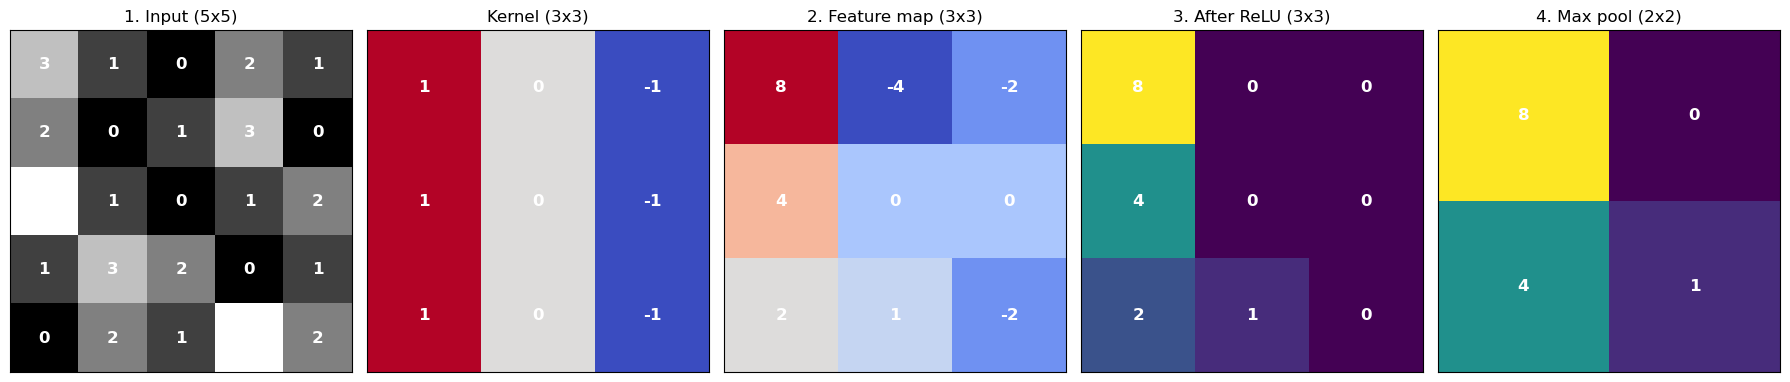

In [10]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
show_grid(axes[0], image, "1. Input (5x5)", "gray")
show_grid(axes[1], kernel, "Kernel (3x3)", "coolwarm")
show_grid(axes[2], feature_map, "2. Feature map (3x3)", "coolwarm")
show_grid(axes[3], relu_out, "3. After ReLU (3x3)")
show_grid(axes[4], pooled, "4. Max pool (2x2)")
plt.tight_layout()
plt.show()

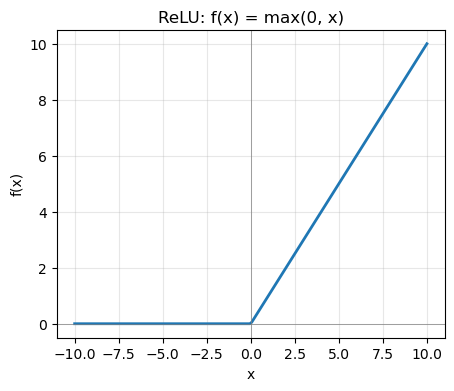

In [11]:
x = np.linspace(-10, 10, 200)

plt.figure(figsize=(5, 4))
plt.plot(x, np.maximum(0, x), linewidth=2)
plt.axhline(0, color="gray", linewidth=0.5)
plt.axvline(0, color="gray", linewidth=0.5)
plt.title("ReLU: f(x) = max(0, x)")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.grid(alpha=0.3)
plt.show()

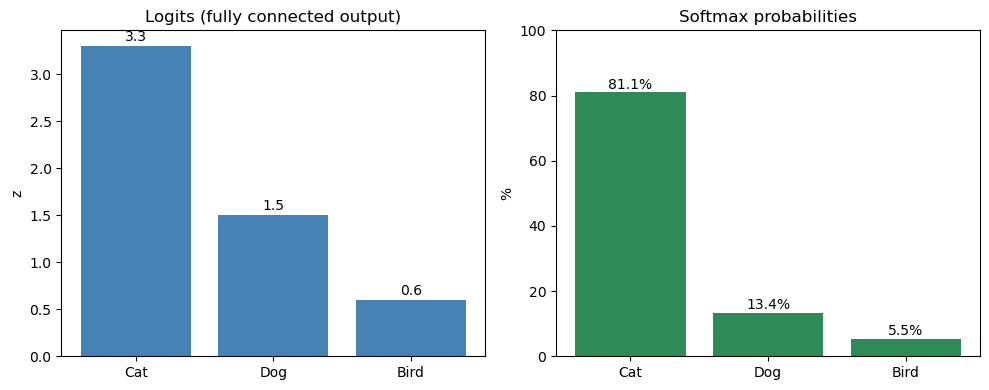

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].bar(classes, z, color="steelblue")
axes[0].set_title("Logits (fully connected output)")
axes[0].set_ylabel("z")
for i, v in enumerate(z):
    axes[0].text(i, v + 0.05, f"{v:.1f}", ha="center")

axes[1].bar(classes, probs * 100, color="seagreen")
axes[1].set_title("Softmax probabilities")
axes[1].set_ylabel("%")
axes[1].set_ylim(0, 100)
for i, v in enumerate(probs * 100):
    axes[1].text(i, v + 1, f"{v:.1f}%", ha="center")

plt.tight_layout()
plt.show()

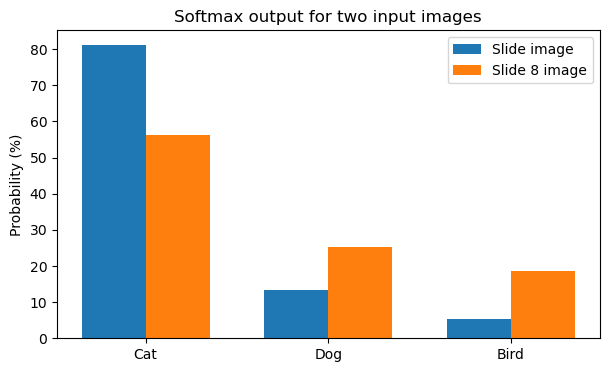

In [13]:
p1 = run_cnn(image)
p2 = run_cnn(image2)

idx = np.arange(len(classes))
w = 0.35

plt.figure(figsize=(7, 4))
plt.bar(idx - w/2, p1 * 100, w, label="Slide image")
plt.bar(idx + w/2, p2 * 100, w, label="Slide 8 image")
plt.xticks(idx, classes)
plt.ylabel("Probability (%)")
plt.title("Softmax output for two input images")
plt.legend()
plt.show()

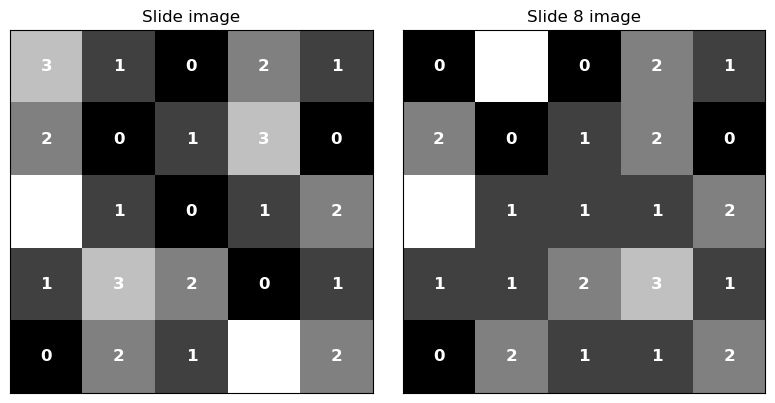

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
show_grid(axes[0], image, "Slide image", "gray")
show_grid(axes[1], image2, "Slide 8 image", "gray")
plt.tight_layout()
plt.show()